# Fashion-MNIST Image Classification

A beginner-friendly project that trains a simple neural network to classify clothing images into 10 categories using TensorFlow/Keras.

## 1. Import libraries

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

## 2. Load the dataset

Fashion-MNIST contains 28×28 grayscale images. Keras downloads the dataset the first time this cell runs.

In [2]:
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", train_images.shape)
print("Test images:", test_images.shape)

Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


## 3. View an image and normalize the data

Pixel values are changed from the range 0–255 to 0–1, which helps the model train.

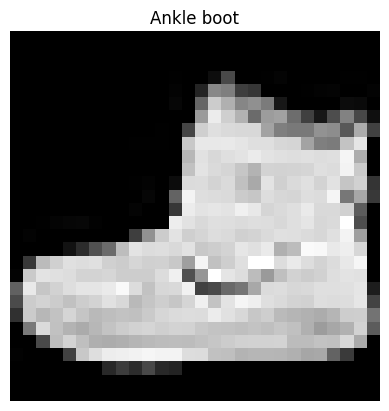

In [3]:
plt.imshow(train_images[0], cmap="gray")
plt.title(class_names[train_labels[0]])
plt.axis("off")
plt.show()

train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

## 4. Build the neural network

`Flatten` turns each 28×28 image into a list of 784 values. The final layer produces scores for the 10 clothing categories.

In [4]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(10)
])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 128)               100480    
                                                                 
 dense_1 (Dense)             (None, 10)                1290      
                                                                 
Total params: 101,770
Trainable params: 101,770
Non-trainable params: 0
_________________________________________________________________


## 5. Train the model

The model uses Adam for optimization and sparse categorical cross-entropy as its loss function.

In [5]:
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

model.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_split=0.1
)

Epoch 1/10
1688/1688 [==============================] - 12s 6ms/step - loss: 0.5059 - accuracy: 0.8220 - val_loss: 0.4106 - val_accuracy: 0.8462
Epoch 2/10
1688/1688 [==============================] - 11s 7ms/step - loss: 0.3753 - accuracy: 0.8648 - val_loss: 0.3580 - val_accuracy: 0.8663
Epoch 3/10
1688/1688 [==============================] - 10s 6ms/step - loss: 0.3389 - accuracy: 0.8752 - val_loss: 0.3479 - val_accuracy: 0.8730
Epoch 4/10
1688/1688 [==============================] - 9s 5ms/step - loss: 0.3131 - accuracy: 0.8858 - val_loss: 0.3454 - val_accuracy: 0.8753
Epoch 5/10
1688/1688 [==============================] - 9s 5ms/step - loss: 0.2974 - accuracy: 0.8908 - val_loss: 0.3399 - val_accuracy: 0.8778
Epoch 6/10
1688/1688 [==============================] - 9s 5ms/step - loss: 0.2806 - accuracy: 0.8958 - val_loss: 0.3416 - val_accuracy: 0.8800
Epoch 7/10
1688/1688 [==============================] - 9s 5ms/step - loss: 0.2699 - accuracy: 0.9005 - val_loss: 0.3347 - val_accura

## 6. Evaluate the model

The test set is kept separate from training and gives an estimate of how well the model handles unseen images.

In [6]:
test_loss, test_accuracy = model.evaluate(test_images, test_labels, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.3630
Test accuracy: 87.62%


## 7. Try a prediction

This predicts the class of one image from the test dataset. Using a dataset image avoids extra image-processing steps.

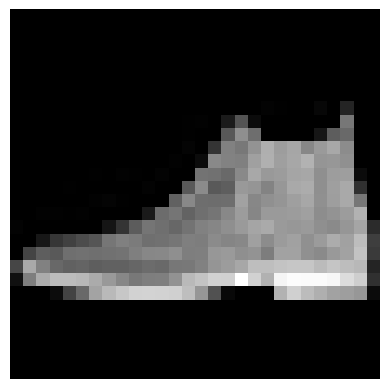

Predicted: Ankle boot
Actual: Ankle boot


In [7]:
image_index = 0
image = test_images[image_index]
scores = model.predict(image[None, ...], verbose=0)
predicted_label = scores[0].argmax()

plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

print("Predicted:", class_names[predicted_label])
print("Actual:", class_names[test_labels[image_index]])

## Summary

This notebook loads Fashion-MNIST, normalizes the images, trains a simple fully connected neural network, evaluates it on the test set, and makes a prediction.

This is a baseline model. Real-world photos may require additional image preprocessing and are not guaranteed to be classified reliably.